[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/18_anomaly_detection.ipynb)

# 18 · Anomaly Detection: Learning What Normal Looks Like

**Part 2 — Classical unsupervised learning** · Notebook 18 of 27

A credit card is used in two countries an hour apart. A sensor on a jet engine starts reading slightly hot. A self-driving car's camera sees an object unlike anything in its training data. A power grid's load pattern shifts at 3 a.m. In each case the interesting event is **rare**, often has **never been seen before**, and there's no labeled dataset of "all the ways things can go wrong". What we do have is plenty of **normal** data.

Anomaly detection turns that around: learn what normal looks like, then flag whatever doesn't fit. This notebook covers the three families from ISYE 4600: **statistical** methods (model the density of normal data and flag low-density points), **geometric** methods (draw a boundary around normal data, like the one-class SVM), and **sequential** methods (accumulate evidence over time to catch a change as soon as possible, like CUSUM). Along the way, hypothesis testing gives us the language for the central trade-off: false alarms against missed detections.

**What you'll learn**

1. Outliers, novelties, and out-of-distribution inputs
2. Density-based detection with a Gaussian, and the **Mahalanobis distance**
3. Thresholds as hypothesis tests: controlling the false-alarm rate
4. **Robust covariance**: when the outliers corrupt the model of normal
5. Kernel density estimation
6. **One-class SVM**: the smallest ball around the data, its dual, and kernels
7. Isolation forests and local outlier factor
8. A real novelty-detection task, compared across methods
9. The likelihood ratio test and the Neyman–Pearson lemma
10. **CUSUM**: detecting a change point in a stream
11. Change detection in networks

*Course map: ISYE 4600 W11 (Anomaly Detection: outlier/novelty/OOD detection, density-based detection, Gaussian and Mahalanobis, robust covariance (MCD), one-class SVM primal/dual/kernels, hypothesis testing view, likelihood ratio test, CUSUM, network change detection, method comparison) and HW4 Q5(4), Q6, Q7 (one-class SVM for novelty detection, CUSUM, one-class SVM dual).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from scipy.stats import chi2, norm, multivariate_normal
from scipy.optimize import minimize
from sklearn.covariance import EmpiricalCovariance, MinCovDet
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, KernelDensity
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer, make_blobs, make_moons
from sklearn.metrics import roc_auc_score, roc_curve
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Outliers, novelties, and out-of-distribution inputs

ISYE W11 distinguishes three settings that use similar tools:

| Setting | Training data | Question | Example |
|---|---|---|---|
| **Outlier detection** | contaminated: normal points *and* some anomalies, unlabeled | which training points are far from the rest? | cleaning sensor glitches before fitting a model |
| **Novelty detection** | clean: normal points only | is this *new* point unlike the training data? | fraud, machine faults, spam (HW4) |
| **Out-of-distribution (OOD) detection** | a labeled classification dataset | is this input outside what the classifier was trained on? | a self-driving car meeting an unseen object |

OOD detection matters because a classifier always outputs *some* class. Trained on cats and dogs, it will confidently call a toaster a dog. A classifier can be accurate on its test set and still be unsafe if it can't say "I've never seen anything like this."

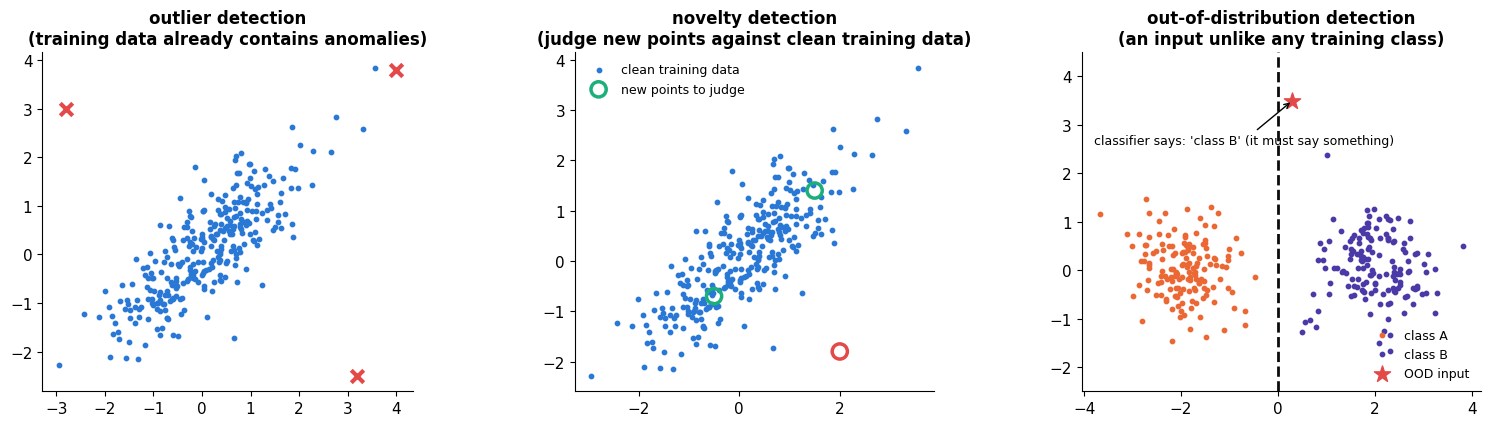

In [2]:
r_ = np.random.default_rng(0)
normal_pts = r_.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], 300)
glitches = np.array([[3.2, -2.5], [-2.8, 3.0], [4.0, 3.8]])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].scatter(*normal_pts.T, s=10, color=C["blue"]); axes[0].scatter(*glitches.T, s=80, color=C["red"], marker="x", lw=3)
axes[0].set(title="outlier detection\n(training data already contains anomalies)")
axes[1].scatter(*normal_pts.T, s=10, color=C["blue"], label="clean training data")
new_pts = np.array([[1.5, 1.4], [2.0, -1.8], [-0.5, -0.7]])
axes[1].scatter(*new_pts.T, s=120, facecolors="none", edgecolors=[C["aqua"], C["red"], C["aqua"]], lw=2.5, label="new points to judge")
axes[1].set(title="novelty detection\n(judge new points against clean training data)"); axes[1].legend(fontsize=9, loc="upper left")
Xc, yc = make_blobs(300, centers=[(-2, 0), (2, 0)], cluster_std=0.6, random_state=1)
axes[2].scatter(*Xc[yc == 0].T, s=10, color=C["orange"], label="class A"); axes[2].scatter(*Xc[yc == 1].T, s=10, color=C["violet"], label="class B")
axes[2].axvline(0, color=C["ink"], ls="--"); axes[2].scatter([0.3], [3.5], s=150, marker="*", color=C["red"], label="OOD input")
axes[2].annotate("classifier says: 'class B' (it must say something)", (0.3, 3.5), xytext=(-3.8, 2.6), fontsize=9, arrowprops=dict(arrowstyle="->"))
axes[2].set(title="out-of-distribution detection\n(an input unlike any training class)", ylim=(-2.5, 4.5)); axes[2].legend(fontsize=9, loc="lower right")
for ax in axes: ax.set(aspect="equal"); ax.grid(False)
fig.tight_layout(); plt.show()

Notice the middle panel: the point at (2, −1.8) is not far from the origin in plain distance, but it lies **against the grain** of the correlated cloud. Measuring "far" correctly is the subject of the next section.

---
## 2. Density-based detection and the Mahalanobis distance

The statistical recipe (ISYE W11): fit a density $\hat f_0(x)$ to normal data, choose a threshold $\varepsilon$, and declare an anomaly whenever $\hat f_0(x) \le \varepsilon$.

The simplest density is a multivariate Gaussian, $\hat f_0(x) = \mathcal{N}(x \mid \hat\mu, \hat\Sigma)$ with the sample mean and covariance (notebook 02). Take logs: the density is low exactly when

$$(x - \hat\mu)^\top\hat\Sigma^{-1}(x - \hat\mu) \;\ge\; b,$$

for a threshold $b$ that corresponds to $\varepsilon$. The left side is the squared **Mahalanobis distance**. It measures distance in units of the data's own spread, along the data's own axes: one step along the long axis of the cloud counts less than one step across it. Compare the contours of constant distance:

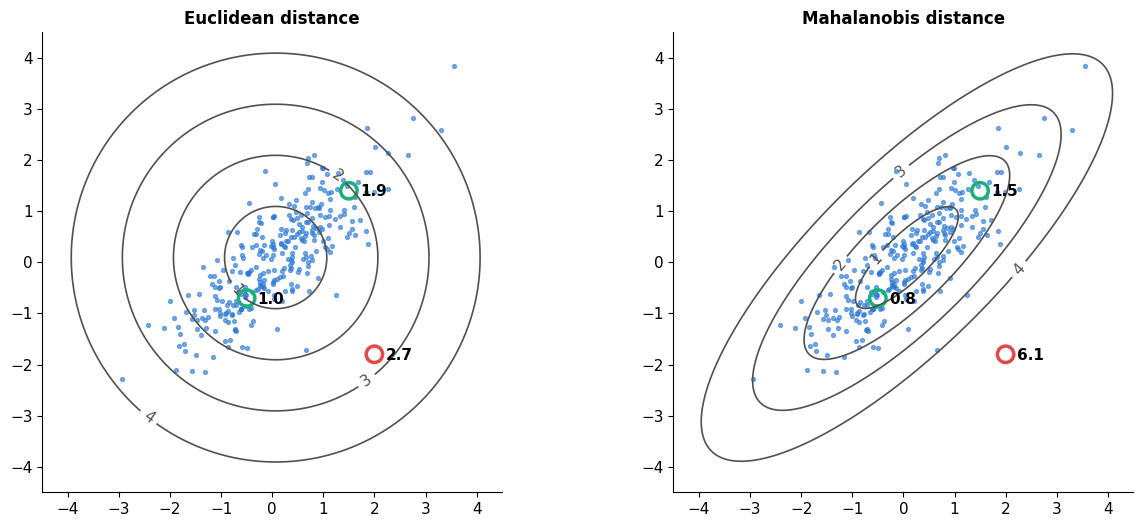

In [3]:
mu_hat = normal_pts.mean(0); S_hat = np.cov(normal_pts.T, bias=True); S_inv = np.linalg.inv(S_hat)
def mahal2(X, mu=mu_hat, Sinv=S_inv):
    D = np.atleast_2d(X) - mu; return np.einsum("ij,jk,ik->i", D, Sinv, D)

gx, gy = np.meshgrid(np.linspace(-4.5, 4.5, 300), np.linspace(-4.5, 4.5, 300)); G = np.column_stack([gx.ravel(), gy.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, (Dg, nm) in zip(axes, [(np.sqrt(((G - mu_hat) ** 2).sum(1)), "Euclidean distance"), (np.sqrt(mahal2(G)), "Mahalanobis distance")]):
    cs = ax.contour(gx, gy, Dg.reshape(gx.shape), levels=[1, 2, 3, 4], colors=[C["muted"]], linewidths=1.2); ax.clabel(cs, fmt="%d")
    ax.scatter(*normal_pts.T, s=8, color=C["blue"], alpha=0.6)
    for p, col in zip(new_pts, [C["aqua"], C["red"], C["aqua"]]):
        d = np.sqrt(((p - mu_hat) ** 2).sum()) if nm.startswith("Euc") else np.sqrt(mahal2(p))[0]
        ax.scatter(*p, s=140, facecolors="none", edgecolors=col, lw=2.5); ax.annotate(f"{d:.1f}", p, xytext=(8, -4), textcoords="offset points", fontsize=11, weight="bold")
    ax.set(aspect="equal", title=nm); ax.grid(False)
fig.tight_layout(); plt.show()

In Euclidean distance, the red point (2, −1.8) and the aqua point (1.5, 1.4) are similarly far from the center (2.7 vs. 1.9). In Mahalanobis distance, the aqua point is an ordinary 1.5, while the red one is above 6: almost no normal data lives in that direction. The Mahalanobis contours are the Gaussian's own density contours, tilted ellipses that follow the data.

---
## 3. Thresholds as hypothesis tests

Where should the threshold go? ISYE W11 frames anomaly detection as a **hypothesis test**:

- $H_0$: $x$ comes from the normal distribution $f_0$ (null hypothesis: normal behavior).
- $H_1$: $x$ does not come from $f_0$ (anomaly).

The anomaly score is the test statistic. Two kinds of mistakes:

| | $H_0$ true (normal) | $H_0$ false (anomaly) |
|---|---|---|
| **flag it** (reject $H_0$) | **Type I error: false alarm** | correct detection |
| **let it pass** | correct | **Type II error: miss** |

Without examples of anomalies we can't measure misses, but we **can** control false alarms. If normal data really is Gaussian in $d$ dimensions, the squared Mahalanobis distance follows a **chi-squared distribution** with $d$ degrees of freedom. So setting $b = \chi^2_{d}(1 - \alpha)$ (the $1-\alpha$ quantile) gives a false-alarm rate of $\alpha$. 🎚️ **Choose the false-alarm rate:**

In [4]:
fresh = np.random.default_rng(5).multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], 20000)     # new NORMAL data
def threshold_demo(alpha=0.01):
    b = chi2.ppf(1 - alpha, df=2)
    flagged = mahal2(fresh) > b
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    d2 = mahal2(fresh); xs = np.linspace(0, 20, 400)
    axes[0].hist(d2, bins=80, range=(0, 20), density=True, color=C["light"], label="squared Mahalanobis distance of normal data")
    axes[0].plot(xs, chi2.pdf(xs, 2), color=C["blue"], lw=2, label="χ² with 2 degrees of freedom")
    axes[0].axvline(b, color=C["red"], lw=2, label=f"threshold b = {b:.2f}")
    axes[0].fill_between(xs[xs >= b], chi2.pdf(xs[xs >= b], 2), color=C["red"], alpha=0.3)
    axes[0].set(xlabel="squared Mahalanobis distance", ylabel="density", title=f"target false-alarm rate α = {alpha:.3f}"); axes[0].legend(fontsize=9)
    axes[1].scatter(*fresh[~flagged][:3000].T, s=3, color=C["blue"], alpha=0.4); axes[1].scatter(*fresh[flagged].T, s=6, color=C["red"])
    axes[1].contour(gx, gy, mahal2(G).reshape(gx.shape), levels=[b], colors=[C["red"]])
    axes[1].set(aspect="equal", xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), title=f"on 20,000 NEW normal points: {flagged.mean():.2%} flagged (false alarms)"); axes[1].grid(False)
    fig.tight_layout(); plt.show()

interact(threshold_demo, alpha=FloatSlider(value=0.01, min=0.001, max=0.2, step=0.001, readout_format=".3f", description="α"));

The observed false-alarm rate on fresh normal data matches the target α closely. The catch is the word *if*: the guarantee holds only when normal data really is Gaussian and the parameters are estimated well. In practice people often set the threshold empirically instead: flag anything beyond the 99th percentile of the training scores.

> 🤔 **Question: Why does ISYE say false alarms are often more costly than misses?**
>
> Because anomalies are rare, even a small false-alarm rate produces mostly false alarms. Suppose 1 transaction in 10,000 is fraud, the detector catches 99% of frauds, and it falsely flags 1% of legitimate ones. Out of a million transactions: 99 frauds caught, but about 10,000 legitimate customers flagged. **99% of the alerts are false.** Analysts stop trusting a system that cries wolf, and customers leave. (This is the base-rate effect from Bayes' rule, notebook 02, and the precision–recall trade-off from notebook 10.) The costs depend on the application, though: missing a failing aircraft engine is worse than any false alarm.

---
## 4. Robust covariance: when the outliers corrupt the model of normal

In **outlier** detection the training data contains the anomalies we want to find. They inflate the estimated covariance, which stretches the ellipse, which makes the anomalies look less anomalous: they **mask** themselves (ISYE W11).

The fix is to estimate the mean and covariance from the "core" of the data. The **minimum covariance determinant** (MCD) estimator finds the subset of $h$ points (say, 75% of the data) whose covariance matrix has the **smallest determinant**: the tightest cluster, which is unlikely to include the outliers. Searching all subsets is hopeless, but the FAST-MCD algorithm (Rousseeuw & Van Driessen, 1999) uses a simple iteration called a **C-step**: compute the mean and covariance of the current subset, then replace the subset by the $h$ points with the smallest Mahalanobis distances under them. Each C-step can only shrink the determinant, so it converges, and running it from several random starts finds a good subset.

determinant of the covariance:  all data 3.151   our MCD subset 0.387   scikit-learn MinCovDet raw 0.387


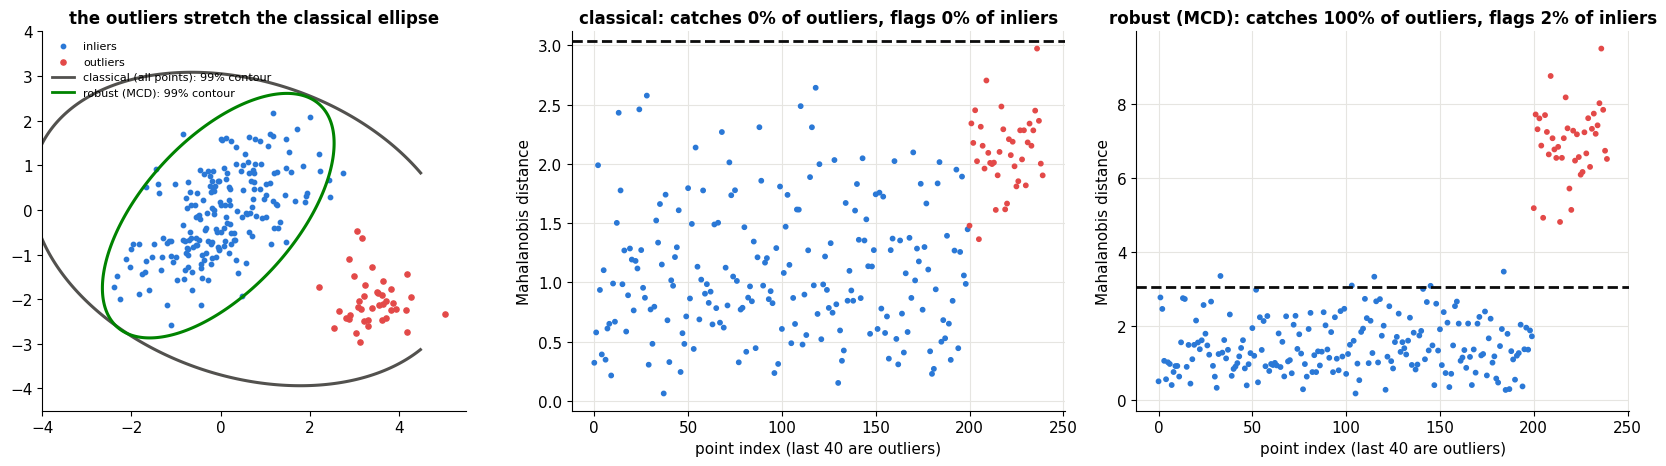

In [5]:
r_ = np.random.default_rng(2)
inl = r_.multivariate_normal([0, 0], [[1, 0.6], [0.6, 1]], 200)
outl = r_.multivariate_normal([3.5, -2.0], [[0.25, 0], [0, 0.25]], 40)       # a cluster of 40 outliers (17%)
Xmix = np.vstack([inl, outl]); is_out = np.r_[np.zeros(200, bool), np.ones(40, bool)]

def fast_mcd(X, h_frac=0.75, n_starts=30, seed=0):
    rr = np.random.default_rng(seed); m, d = X.shape; h = int(h_frac * m); best = (np.inf, None)
    for _ in range(n_starts):
        sub = rr.choice(m, d + 1, replace=False)               # start from a tiny random subset
        for _ in range(30):                                    # C-steps
            mu_s, S_s = X[sub].mean(0), np.cov(X[sub].T, bias=True) + 1e-9 * np.eye(d)
            D = mahal2(X, mu_s, np.linalg.inv(S_s))
            new = np.argsort(D)[:h]                            # keep the h points closest under this fit
            if set(new) == set(sub): break
            sub = new
        det = np.linalg.det(np.cov(X[sub].T, bias=True))
        if det < best[0]: best = (det, sub)
    sub = best[1]; return X[sub].mean(0), np.cov(X[sub].T, bias=True), sub

mu_r, S_r, core = fast_mcd(Xmix)
mu_c, S_c = Xmix.mean(0), np.cov(Xmix.T, bias=True)
sk_mcd = MinCovDet(support_fraction=0.75, random_state=0).fit(Xmix)
print(f"determinant of the covariance:  all data {np.linalg.det(S_c):.3f}   our MCD subset {np.linalg.det(S_r):.3f}   scikit-learn MinCovDet raw {np.linalg.det(sk_mcd.raw_covariance_):.3f}")

d_classic = mahal2(Xmix, mu_c, np.linalg.inv(S_c)); d_robust = mahal2(Xmix, mu_r, np.linalg.inv(S_r))
b = chi2.ppf(0.99, 2)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
ax.scatter(*inl.T, s=10, color=C["blue"], label="inliers"); ax.scatter(*outl.T, s=14, color=C["red"], label="outliers")
for mu_, S_, col, nm in [(mu_c, S_c, C["muted"], "classical (all points)"), (mu_r, S_r, C["green"], "robust (MCD)")]:
    ax.contour(gx, gy, mahal2(G, mu_, np.linalg.inv(S_)).reshape(gx.shape), levels=[b], colors=[col], linewidths=2.2)
    ax.plot([], [], color=col, label=f"{nm}: 99% contour")
ax.set(aspect="equal", xlim=(-4, 5.5), ylim=(-4.5, 4), title="the outliers stretch the classical ellipse"); ax.legend(fontsize=8, loc="upper left"); ax.grid(False)
for ax, d, nm in [(axes[1], d_classic, "classical"), (axes[2], d_robust, "robust (MCD)")]:
    ax.scatter(np.arange(240), np.sqrt(d), s=10, c=np.where(is_out, C["red"], C["blue"]))
    ax.axhline(np.sqrt(b), color=C["ink"], ls="--")
    caught = (d[is_out] > b).mean(); fa = (d[~is_out] > b).mean()
    ax.set(xlabel="point index (last 40 are outliers)", ylabel="Mahalanobis distance", title=f"{nm}: catches {caught:.0%} of outliers, flags {fa:.0%} of inliers")
fig.tight_layout(); plt.show()

With the classical estimate, the outlier cluster drags the mean toward itself and stretches the covariance in its direction, so every outlier ends up inside the 99% contour: completely masked. The MCD fit locks onto the 75% tightest points (the inliers) and the outliers stand out at distances far beyond the threshold. Our from-scratch C-steps find a subset with the same tiny determinant as scikit-learn's `MinCovDet`.

---
## 5. Kernel density estimation

A Gaussian assumes one elliptical blob. For data with several clusters or odd shapes, use a **nonparametric** density: **kernel density estimation** (KDE) places a small bump (kernel) of width $h$ on every training point and adds them up,

$$\hat f_0(x) = \frac{1}{m}\sum_{i=1}^{m} K_h(x - x^i), \qquad K_h(u) = \frac{1}{(2\pi h^2)^{d/2}}e^{-\|u\|^2/2h^2}.$$

The bandwidth $h$ is everything. 🎚️ **Change it:**

In [6]:
Xk = np.vstack([make_moons(300, noise=0.07, random_state=0)[0], np.random.default_rng(1).normal([2.6, 1.2], 0.15, (60, 2))])
gx2, gy2 = np.meshgrid(np.linspace(-1.6, 3.2, 220), np.linspace(-1.0, 1.8, 160)); G2 = np.column_stack([gx2.ravel(), gy2.ravel()])
def kde_demo(bandwidth=0.15, flag_percent=2.0):
    kde = KernelDensity(bandwidth=bandwidth).fit(Xk)
    logd = kde.score_samples(G2).reshape(gx2.shape)
    thr = np.percentile(kde.score_samples(Xk), flag_percent)  # flag the lowest-density x% of training points
    fig, ax = plt.subplots(figsize=(9.5, 5))
    ax.contourf(gx2, gy2, np.exp(logd), levels=25, cmap="Blues")
    ax.contour(gx2, gy2, logd, levels=[thr], colors=[C["red"]], linewidths=2)
    ax.scatter(*Xk.T, s=6, color=C["ink"], alpha=0.6)
    ax.set(aspect="equal", title=f"KDE, bandwidth h = {bandwidth:.2f}: red = boundary of the 'normal' region ({100 - flag_percent:.0f}% of training data inside)"); ax.title.set_fontsize(10); ax.grid(False)
    plt.show()

interact(kde_demo, bandwidth=FloatSlider(value=0.15, min=0.02, max=0.8, step=0.01, description="h"),
         flag_percent=FloatSlider(value=2.0, min=0.5, max=10, step=0.5, description="flag %"));

Small $h$: the density is a spiky sum of individual points and the "normal region" breaks into tiny islands (overfitting: any new point that isn't right on top of a training point looks anomalous). Large $h$: everything blurs into one blob that covers the gaps between the moons (underfitting). Around $h \approx 0.1$–$0.2$ the boundary follows the two moons and the small cluster.

KDE's weakness (ISYE: *"the main challenge is estimating the density reliably in high dimensions"*): the number of points needed to fill space grows exponentially with dimension (notebook 10's curse of dimensionality), so in 50 dimensions almost every point sits in a nearly empty neighborhood. That motivates methods that skip density estimation.

---
## 6. One-class SVM: the smallest ball around the data

ISYE's geometric view: instead of estimating a density and thresholding it, **directly learn the boundary** of the normal region (its *support*). The cleanest version: find the **smallest ball** that contains all the training data,

$$\min_{r,\,c}\; r^2 \quad \text{s.t.}\quad \|x^i - c\|^2 \le r^2 \;\;\forall i, \qquad r \ge 0.$$

This is the anomaly-detection cousin of the SVM's margin maximization (notebook 11). Same machinery, too. The Lagrangian is $L = r^2 + \sum_i\alpha_i(\|x^i - c\|^2 - r^2)$ with $\alpha_i \ge 0$. Setting derivatives to zero:

$$\frac{\partial L}{\partial r} = 2r - 2r\sum_i\alpha_i = 0 \;\Rightarrow\; \sum_i\alpha_i = 1, \qquad \frac{\partial L}{\partial c} = \sum_i\alpha_i(-2x^i + 2c) = 0 \;\Rightarrow\; c = \sum_i\alpha_ix^i.$$

The center is a **weighted average** of the data. Substituting back gives the dual (ISYE W11, HW4 Q7):

$$\max_{\alpha}\; \sum_i\alpha_i\,x^{i\top}x^i - \sum_i\sum_j\alpha_i\alpha_j\,x^{i\top}x^j \qquad\text{s.t.}\quad \sum_i\alpha_i = 1,\;\; \alpha_i \ge 0.$$

A quadratic program that depends on the data only through **inner products**. **Complementary slackness** says $\alpha_i(\|x^i - c\|^2 - r^2) = 0$: points strictly inside the ball get $\alpha_i = 0$, and only points **on** the boundary can have $\alpha_i > 0$. Those are the **support vectors**, and they alone determine the ball. Let's solve the dual directly:

center c* = Σ αᵢ xⁱ = [ 0.023 -0.022],  radius r = 2.680
support vectors: 3 of 40 points have αᵢ > 0:  α = [0.304 0.439 0.257]
max distance from c* to any point: 2.680  (= r: every point is inside, the SVs on the boundary)


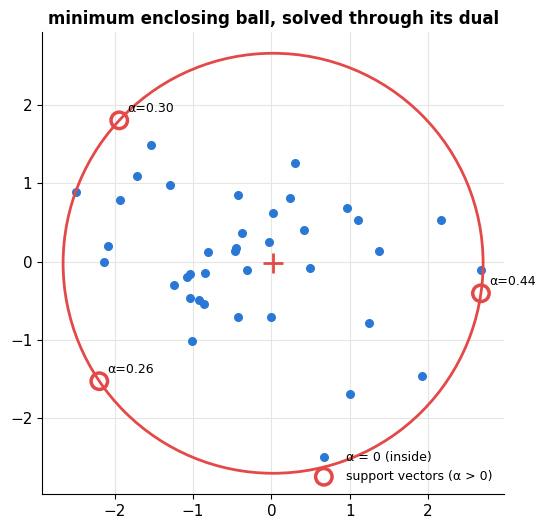

In [7]:
def min_enclosing_ball(X, C_box=1.0, kernel=lambda A, B: A @ B.T, kdiag=lambda Z: (Z ** 2).sum(1)):
    """Dual of the (soft) minimum enclosing ball: max bᵀα − αᵀKα, Σα = 1, 0 ≤ α ≤ C. C = 1 means a hard ball."""
    K = kernel(X, X); b_ = np.diag(K); m = len(X)
    res = minimize(lambda a: -(b_ @ a - a @ K @ a), np.full(m, 1 / m), jac=lambda a: -(b_ - 2 * K @ a),
                   bounds=[(0, C_box)] * m, constraints=[{"type": "eq", "fun": lambda a: a.sum() - 1}], method="SLSQP", options=dict(maxiter=500, ftol=1e-12))
    alpha = res.x * (res.x > 1e-6); alpha /= alpha.sum()
    on_boundary = (alpha > 1e-6) & (alpha < C_box - 1e-6)     # free support vectors sit exactly on the sphere
    dist2 = lambda Z: kdiag(Z) - 2 * kernel(Z, X) @ alpha + alpha @ K @ alpha   # ||φ(z) − c||², via kernels only
    r2 = dist2(X[on_boundary]).mean() if on_boundary.any() else dist2(X[alpha > 1e-6]).max()
    return alpha, r2, dist2

r_ = np.random.default_rng(4)
Xb = r_.normal(0, 1, (40, 2)) * [1.3, 0.8]
alpha, r2, dist2 = min_enclosing_ball(Xb)
c_star = alpha @ Xb
sv = alpha > 1e-6
print(f"center c* = Σ αᵢ xⁱ = {c_star.round(3)},  radius r = {np.sqrt(r2):.3f}")
print(f"support vectors: {sv.sum()} of {len(Xb)} points have αᵢ > 0:  α = {alpha[sv].round(3)}")
print(f"max distance from c* to any point: {np.sqrt(dist2(Xb).max()):.3f}  (= r: every point is inside, the SVs on the boundary)")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(*Xb[~sv].T, s=30, color=C["blue"], label="α = 0 (inside)")
ax.scatter(*Xb[sv].T, s=140, facecolors="none", edgecolors=C["red"], lw=2.5, label="support vectors (α > 0)")
ax.add_patch(plt.Circle(c_star, np.sqrt(r2), fill=False, color=C["red"], lw=2)); ax.scatter(*c_star, marker="+", s=200, color=C["red"])
for i in np.flatnonzero(sv): ax.annotate(f"α={alpha[i]:.2f}", Xb[i], xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.set(aspect="equal", title="minimum enclosing ball, solved through its dual"); ax.legend(loc="lower right", fontsize=9); plt.show()

Only three of the 40 points (the ones touching the circle) have nonzero α, as complementary slackness predicts. (In 2-D a ball is pinned down by at most three boundary points; sometimes two diametrically opposite points suffice, each with α = 0.5.) the solution is **sparse**, so storage and prediction cost depend only on the support vectors.

### Soft boundaries and kernels

A hard ball has two problems: a single outlier in the training data can inflate it arbitrarily, and a ball is a poor shape for most data. Both fixes come from the SVM toolbox (notebook 11):

- **Slack.** Let some training points fall outside, at a cost: $\min r^2 + C\sum_i\xi_i$ s.t. $\|x^i - c\|^2 \le r^2 + \xi_i$. In the dual this just adds an upper bound $\alpha_i \le C$. This is **support vector data description** (SVDD; Tax & Duin, 2004). Points outside the ball get $\alpha_i = C$.
- **Kernels.** Replace every inner product $x^{i\top}x^j$ with a kernel $k(x^i, x^j)$. The ball now lives in the kernel's feature space, and in the original space its boundary can wrap around complicated shapes. With an RBF kernel, $k(x, x) = 1$ for every $x$, and the problem becomes equivalent to Schölkopf's **one-class SVM** (separate the data from the origin with maximum margin in feature space), which is what `sklearn.svm.OneClassSVM` implements. Its parameter $\nu$ is an upper bound on the fraction of training points left outside (and a lower bound on the fraction of support vectors).

🎚️ **Explore ν and the RBF width γ** on clean training data (blue), then judge new test points: some normal (aqua), some anomalous (red).

In [8]:
r_ = np.random.default_rng(4)
X_train_oc = np.vstack([r_.normal([-1.5, 0], 0.5, (120, 2)), r_.normal([1.5, 0.3], [0.4, 0.8], (120, 2))])
X_test_norm = np.vstack([r_.normal([-1.5, 0], 0.5, (25, 2)), r_.normal([1.5, 0.3], [0.4, 0.8], (25, 2))])
X_test_anom = r_.uniform([-4, -3], [4, 3], (30, 2))
X_test_anom = X_test_anom[np.minimum(np.linalg.norm((X_test_anom - [-1.5, 0]) / 0.5, axis=1), np.linalg.norm((X_test_anom - [1.5, 0.3]) / [0.4, 0.8], axis=1)) > 3]
gx3, gy3 = np.meshgrid(np.linspace(-4, 4, 250), np.linspace(-3, 3, 200)); G3 = np.column_stack([gx3.ravel(), gy3.ravel()])

def ocsvm_demo(nu=0.05, gamma=0.5):
    oc = OneClassSVM(nu=nu, gamma=gamma).fit(X_train_oc)
    Z = oc.decision_function(G3).reshape(gx3.shape)
    fig, ax = plt.subplots(figsize=(10, 5.4))
    ax.contourf(gx3, gy3, Z, levels=np.linspace(Z.min(), 0, 8), cmap="Reds_r", alpha=0.35)
    ax.contour(gx3, gy3, Z, levels=[0], colors=[C["red"]], linewidths=2)
    ax.scatter(*X_train_oc.T, s=10, color=C["blue"], label="training (normal only)")
    ax.scatter(*oc.support_vectors_.T, s=45, facecolors="none", edgecolors=C["ink"], lw=0.8, label=f"support vectors ({len(oc.support_vectors_)})")
    fp = (oc.predict(X_test_norm) == -1).mean(); det = (oc.predict(X_test_anom) == -1).mean()
    ax.scatter(*X_test_norm.T, s=70, marker="^", color=C["aqua"], edgecolor="k", label=f"new normal: {fp:.0%} falsely flagged")
    ax.scatter(*X_test_anom.T, s=70, marker="X", color=C["red"], edgecolor="k", label=f"new anomalies: {det:.0%} detected")
    out_train = (oc.predict(X_train_oc) == -1).mean()
    ax.set(aspect="equal", title=f"one-class SVM, ν = {nu:.2f}, γ = {gamma:.2f}: {out_train:.0%} of training points outside (ν bounds this)")
    ax.legend(loc="upper left", fontsize=8); ax.grid(False); plt.show()

interact(ocsvm_demo, nu=FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01, description="ν"),
         gamma=FloatSlider(value=0.5, min=0.02, max=10.0, step=0.02, description="γ"));

- **γ (kernel width).** Small γ: smooth, blobby boundary that can even merge the two clusters. Large γ: the boundary shrink-wraps individual points and new normal points get flagged (overfitting), exactly like KDE with a tiny bandwidth.
- **ν.** The fraction of training points left outside roughly tracks ν. Larger ν tightens the region: fewer missed anomalies, more false alarms.

Here's the from-scratch soft-ball dual with an RBF kernel next to scikit-learn's one-class SVM, at matching settings:

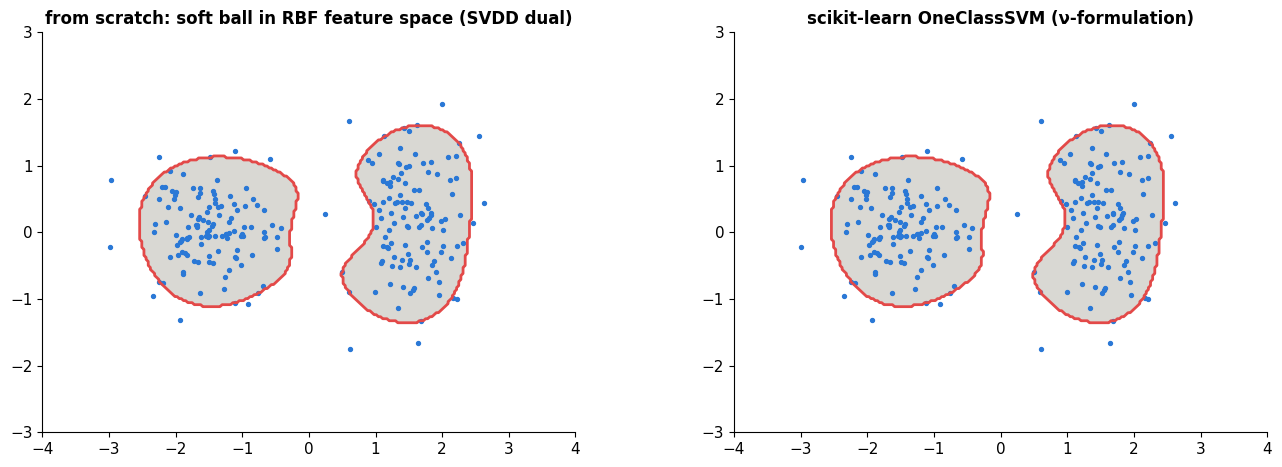

agreement on the grid: 100.0%;  support vectors: ours 29


In [9]:
rbf = lambda A, B, g=0.5: np.exp(-g * np.maximum((A ** 2).sum(1)[:, None] - 2 * A @ B.T + (B ** 2).sum(1)[None, :], 0))
nu_ = 0.1
alpha_k, r2_k, dist2_k = min_enclosing_ball(X_train_oc, C_box=1 / (nu_ * len(X_train_oc)), kernel=rbf, kdiag=lambda Z: np.ones(len(Z)))
ours_inside = (dist2_k(G3) <= r2_k).reshape(gx3.shape)
sk_inside = (OneClassSVM(nu=nu_, gamma=0.5).fit(X_train_oc).decision_function(G3) >= 0).reshape(gx3.shape)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, Zin, nm in [(axes[0], ours_inside, "from scratch: soft ball in RBF feature space (SVDD dual)"), (axes[1], sk_inside, "scikit-learn OneClassSVM (ν-formulation)")]:
    ax.contourf(gx3, gy3, Zin, levels=[0.5, 1.5], colors=[C["light"]]); ax.contour(gx3, gy3, Zin.astype(float), levels=[0.5], colors=[C["red"]], linewidths=2)
    ax.scatter(*X_train_oc.T, s=8, color=C["blue"]); ax.set(aspect="equal", title=nm); ax.grid(False)
fig.tight_layout(); plt.show()
print(f"agreement on the grid: {(ours_inside == sk_inside).mean():.1%};  support vectors: ours {np.sum(alpha_k > 1e-6)}")

The two formulations draw essentially the same region, as theory says they should for an RBF kernel with $C = 1/(\nu m)$.

---
## 7. Isolation forests and local outlier factor

Two more detectors from ISYE's comparison slide, both popular in practice.

**Isolation forest** (Liu, Ting & Zhou, 2008) turns the problem around: instead of describing normal data, measure how **easy a point is to isolate**. Build random trees that split on a random feature at a random value, until every point is alone in a leaf. Anomalies are few and different, so random cuts separate them from everything else after only a few splits; normal points, packed among neighbors, need many. The anomaly score is the **average path length** over many such trees (short = anomalous). No distances, no densities, and it scales to large, high-dimensional data.

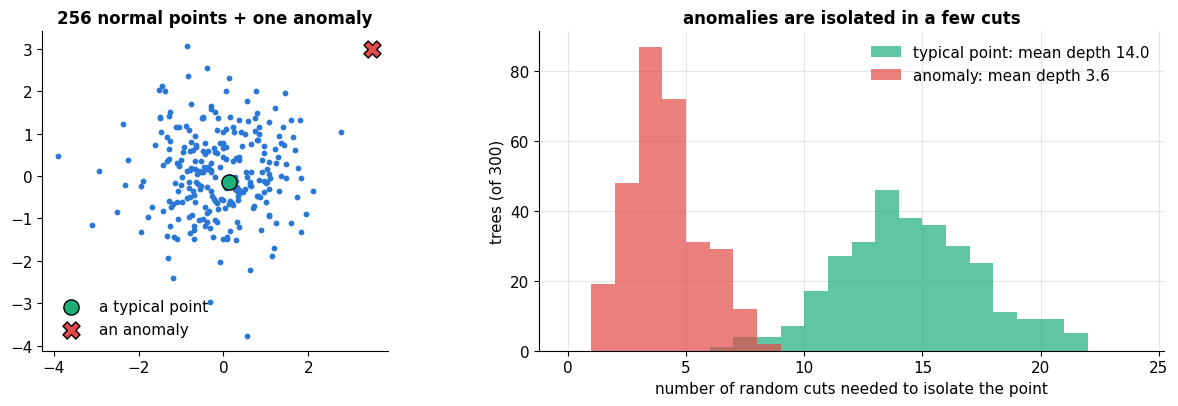

In [10]:
def isolation_depth(X, idx, rr, depth=0, max_depth=30):
    """Depth at which point idx gets isolated by uniformly random axis-aligned cuts (one random tree)."""
    if len(X) <= 1 or depth >= max_depth: return depth
    j = rr.integers(X.shape[1]); lo, hi = X[:, j].min(), X[:, j].max()
    if lo == hi: return depth
    s = rr.uniform(lo, hi); left = X[:, j] < s
    side = left if left[idx] else ~left
    return isolation_depth(X[side], np.flatnonzero(side).tolist().index(idx), rr, depth + 1, max_depth)

r_ = np.random.default_rng(0)
Xi = np.vstack([r_.normal(0, 1, (256, 2)), [[3.5, 3.0]]]); target_out, target_in = 256, 0
rr = np.random.default_rng(1)
d_out = [isolation_depth(Xi, target_out, rr) for _ in range(300)]; d_in = [isolation_depth(Xi, target_in, rr) for _ in range(300)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(*Xi[:-1].T, s=10, color=C["blue"]); axes[0].scatter(*Xi[[target_in]].T, s=120, marker="o", color=C["aqua"], edgecolor="k", label="a typical point")
axes[0].scatter(*Xi[[target_out]].T, s=150, marker="X", color=C["red"], edgecolor="k", label="an anomaly"); axes[0].legend(); axes[0].set(aspect="equal", title="256 normal points + one anomaly"); axes[0].grid(False)
axes[1].hist(d_in, bins=range(0, 25), alpha=0.7, color=C["aqua"], label=f"typical point: mean depth {np.mean(d_in):.1f}")
axes[1].hist(d_out, bins=range(0, 25), alpha=0.7, color=C["red"], label=f"anomaly: mean depth {np.mean(d_out):.1f}")
axes[1].set(xlabel="number of random cuts needed to isolate the point", ylabel="trees (of 300)", title="anomalies are isolated in a few cuts"); axes[1].legend()
fig.tight_layout(); plt.show()

**Local outlier factor** (LOF; Breunig et al., 2000) compares each point's local density (estimated from its $k$ nearest neighbors) with the densities of its neighbors. A point in a sparse region surrounded by sparse neighbors is fine (it's just a sparse cluster); a point much sparser than its own neighbors is an outlier. This handles clusters of **different densities**, which a single global density threshold can't.

---
## 8. A real novelty-detection task

HW4 builds a novelty detector for spam by training a one-class SVM on non-spam emails only. Here's the same setup on the breast-cancer dataset bundled with scikit-learn: train only on **benign** tumors (the "normal" class), then score a test set of new benign and malignant tumors. Malignant ones should look anomalous. The features are log-transformed (they're skewed) and standardized using the training data.

train: 250 benign only.   test: 107 benign + 212 malignant, 30 features


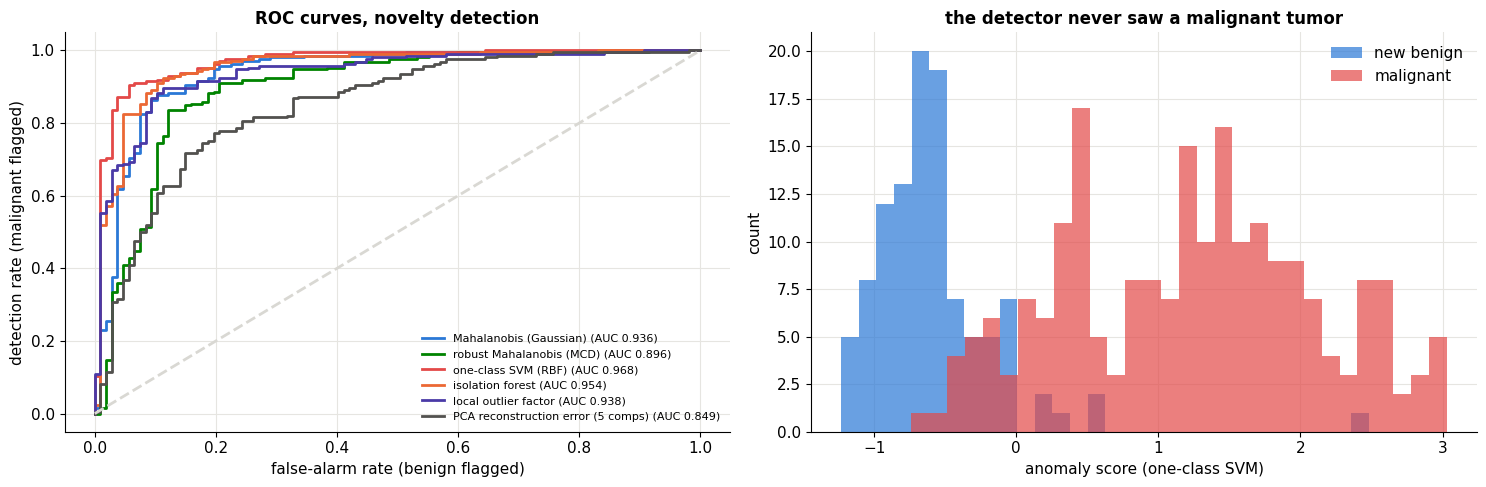

,AUC,detection rate at 5% false alarms
detector,,
Mahalanobis (Gaussian),0.936,0.665
robust Mahalanobis (MCD),0.896,0.410
one-class SVM (RBF),0.968,0.892
isolation forest,0.954,0.825
local outlier factor,0.938,0.689
PCA reconstruction error (5 comps),0.849,0.387


In [11]:
Xbc, ybc = load_breast_cancer(return_X_y=True)          # y = 1 benign, 0 malignant
Xbc = np.log1p(Xbc)
r_ = np.random.default_rng(0); benign = np.flatnonzero(ybc == 1); r_.shuffle(benign)
tr_i, te_i = benign[:250], np.r_[benign[250:], np.flatnonzero(ybc == 0)]
scaler = StandardScaler().fit(Xbc[tr_i]); A_tr, A_te = scaler.transform(Xbc[tr_i]), scaler.transform(Xbc[te_i])
y_te = (ybc[te_i] == 0).astype(int)                     # 1 = anomaly (malignant)
print(f"train: {len(tr_i)} benign only.   test: {np.sum(y_te == 0)} benign + {y_te.sum()} malignant, {A_tr.shape[1]} features")

pca_ = PCA(5).fit(A_tr)
detectors = {
    "Mahalanobis (Gaussian)": lambda: EmpiricalCovariance().fit(A_tr).mahalanobis(A_te),
    "robust Mahalanobis (MCD)": lambda: MinCovDet(random_state=0).fit(A_tr).mahalanobis(A_te),
    "one-class SVM (RBF)": lambda: -OneClassSVM(nu=0.05, gamma=0.01).fit(A_tr).decision_function(A_te),
    "isolation forest": lambda: -IsolationForest(random_state=0).fit(A_tr).score_samples(A_te),
    "local outlier factor": lambda: -LocalOutlierFactor(n_neighbors=20, novelty=True).fit(A_tr).score_samples(A_te),
    "PCA reconstruction error (5 comps)": lambda: ((A_te - pca_.inverse_transform(pca_.transform(A_te))) ** 2).sum(1),
}
scores = {k: f() for k, f in detectors.items()}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
rows = []
for (k, s), col in zip(scores.items(), [C["blue"], C["green"], C["red"], C["orange"], C["violet"], C["muted"]]):
    fpr, tpr, thr = roc_curve(y_te, s); auc = roc_auc_score(y_te, s)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{k} (AUC {auc:.3f})")
    benign_scores = s[y_te == 0]; t95 = np.percentile(benign_scores, 95)          # 5% false alarms on benign
    rows.append({"detector": k, "AUC": auc, "detection rate at 5% false alarms": (s[y_te == 1] > t95).mean()})
axes[0].plot([0, 1], [0, 1], color=C["light"], ls="--"); axes[0].set(xlabel="false-alarm rate (benign flagged)", ylabel="detection rate (malignant flagged)", title="ROC curves, novelty detection"); axes[0].legend(fontsize=8, loc="lower right")
s = scores["one-class SVM (RBF)"]
axes[1].hist(s[y_te == 0], bins=30, alpha=0.7, color=C["blue"], label="new benign"); axes[1].hist(s[y_te == 1], bins=30, alpha=0.7, color=C["red"], label="malignant")
axes[1].set(xlabel="anomaly score (one-class SVM)", ylabel="count", title="the detector never saw a malignant tumor"); axes[1].legend()
fig.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("detector").round(3)

Every detector separates the classes well without ever seeing a malignant example, and the one-class SVM and isolation forest lead. Robust covariance doesn't help here: the training data is clean (novelty detection), so there's nothing for robustness to protect against, and MCD's estimate from 75% of the points is noisier. (Of course, if you *have* labeled malignant examples, a supervised classifier does even better, about 97% accuracy in notebook 08. Anomaly detection is for when you don't, or when tomorrow's anomalies may look different from yesterday's.)

> 🤔 **Question: How do I choose γ and ν without anomaly labels?**
>
> Honestly, it's hard; that's the price of unsupervised detection. Common approaches: set ν to your tolerable false-alarm rate and choose γ so that held-out **normal** data is flagged at about that rate (too large a γ flags far more, a sign of overfitting); use heuristics like $\gamma = 1/(d\cdot\mathrm{Var}(x))$ (scikit-learn's `"scale"`); or, if a few labeled anomalies exist, use them only for validation, never for training. Here we picked γ = 0.01 on the lower side of 1/30 because the features are standardized and 30-dimensional.

---
## 9. The likelihood ratio test

When **both** distributions are known (normal $f_0$ and anomalous $f_1$), the optimal test is known too. The **Neyman–Pearson lemma**: among all tests with false-alarm rate at most α, the one with the highest detection rate decides $H_1$ when the **likelihood ratio** is large,

$$\frac{f_1(x)}{f_0(x)} > b,$$

with $b$ chosen so the false-alarm rate is exactly α. 🎚️ **Move the threshold** for two Gaussians, normal $\mathcal{N}(0, 1)$ and anomalous $\mathcal{N}(\delta, 1)$:

In [12]:
def lrt_demo(threshold=1.6, delta=2.0):
    xs = np.linspace(-4, 7, 600)
    f0, f1 = norm.pdf(xs, 0, 1), norm.pdf(xs, delta, 1)
    alpha_, power = 1 - norm.cdf(threshold), 1 - norm.cdf(threshold - delta)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    ax = axes[0]
    ax.plot(xs, f0, color=C["blue"], lw=2, label="f₀: normal N(0, 1)"); ax.plot(xs, f1, color=C["red"], lw=2, label=f"f₁: anomaly N({delta:.1f}, 1)")
    ax.fill_between(xs[xs >= threshold], f0[xs >= threshold], color=C["blue"], alpha=0.35, label=f"type I (false alarm) = {alpha_:.3f}")
    ax.fill_between(xs[xs < threshold], f1[xs < threshold], color=C["red"], alpha=0.25, label=f"type II (miss) = {1 - power:.3f}")
    ax.axvline(threshold, color=C["ink"], ls="--"); ax.set(xlabel="x", title="flag x when it's above the threshold"); ax.legend(fontsize=8, loc="upper right")
    ts = np.linspace(-4, 8, 400)
    axes[1].plot(1 - norm.cdf(ts), 1 - norm.cdf(ts - delta), color=C["violet"], lw=2, label="ROC of the likelihood ratio test")
    axes[1].scatter([alpha_], [power], s=90, color=C["ink"], zorder=3)
    axes[1].plot([0, 1], [0, 1], color=C["light"], ls="--"); axes[1].set(xlabel="false-alarm rate", ylabel="detection rate", title=f"no test does better than this curve (δ = {delta:.1f})"); axes[1].legend(loc="lower right")
    fig.tight_layout(); plt.show()

interact(lrt_demo, threshold=FloatSlider(value=1.6, min=-2, max=5, step=0.05, description="threshold"), delta=FloatSlider(value=2.0, min=0.2, max=5, step=0.1, description="shift δ"));

For equal-variance Gaussians the log-likelihood ratio is $\delta x - \delta^2/2$, increasing in $x$, so "ratio > $b$" is just "$x$ > threshold". Raising the threshold trades misses for false alarms, along the ROC curve. The bigger the shift δ, the more the distributions separate and the closer the curve hugs the top-left corner. For a small shift (δ = 0.5, say), no threshold works well on a **single** observation: the distributions overlap too much. The fix is to combine many observations over time, which is what the next section does.

---
## 10. CUSUM: detecting a change point in a stream

In monitoring, data arrives one point at a time: sensor readings, daily sales, network traffic. At some unknown time $\kappa$ the distribution may change from $f_0$ to $f_1$, and we want to raise an alarm **as soon as possible after** the change while rarely raising one before. A single slightly-unusual point proves little; a run of them is convincing. CUSUM (Page, 1954) accumulates the evidence (ISYE W11):

$$W_0 = 0, \qquad W_k = \max\Big(W_{k-1} + \log\frac{f_1(X_k)}{f_0(X_k)},\; 0\Big), \qquad \text{alarm when } W_k > b.$$

Each observation adds its log-likelihood ratio: positive if it looks more like $f_1$, negative if more like $f_0$. Before the change the increments are negative on average and the $\max(\cdot, 0)$ keeps $W$ pinned near zero ("forget evidence that only supports normal"). After the change they're positive on average and $W$ climbs steadily. **History matters**: a modest but persistent shift adds up.

For a mean shift from $\mathcal{N}(0, \sigma^2)$ to $\mathcal{N}(\delta, \sigma^2)$, the increment is $\log\frac{f_1(x)}{f_0(x)} = \frac{\delta}{\sigma^2}\big(x - \frac{\delta}{2}\big)$: CUSUM adds up how far each observation is above the halfway point between the two means. Let's catch a small shift, δ = 0.75σ, at time 100:

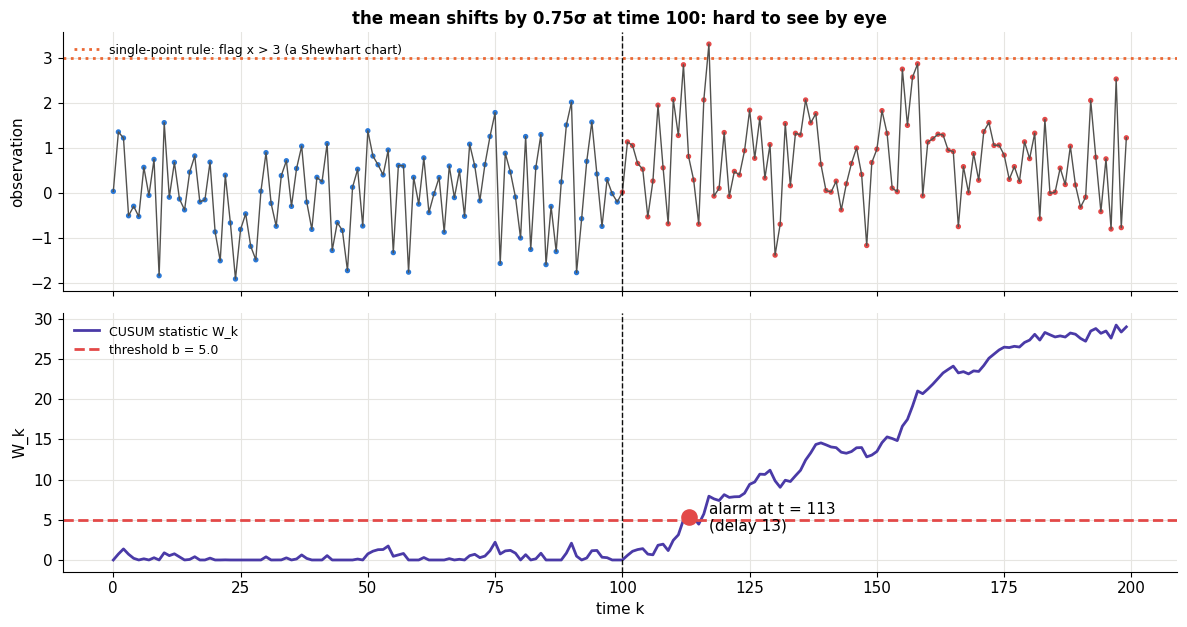

points above 3 after the change: 1 of 100   (the single-point rule barely ever fires for a small shift)


In [13]:
def cusum(x, llr):
    W = np.zeros(len(x) + 1)
    for k, xk in enumerate(x, 1): W[k] = max(W[k - 1] + llr(xk), 0.0)
    return W[1:]

delta_, kappa = 0.75, 100
r_ = np.random.default_rng(11)
stream = np.r_[r_.normal(0, 1, kappa), r_.normal(delta_, 1, 100)]
llr_shift = lambda x: delta_ * (x - delta_ / 2)
W = cusum(stream, llr_shift); b_cusum = 5.0
alarm = np.argmax(W > b_cusum) if (W > b_cusum).any() else None

fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
axes[0].plot(stream, color=C["muted"], lw=1); axes[0].scatter(range(len(stream)), stream, s=8, c=np.where(np.arange(len(stream)) < kappa, C["blue"], C["red"]))
axes[0].axhline(3, color=C["orange"], ls=":", label="single-point rule: flag x > 3 (a Shewhart chart)"); axes[0].axvline(kappa, color=C["ink"], ls="--", lw=1)
axes[0].set(ylabel="observation", title=f"the mean shifts by {delta_}σ at time {kappa}: hard to see by eye"); axes[0].legend(loc="upper left", fontsize=9)
axes[1].plot(W, color=C["violet"], lw=2, label="CUSUM statistic W_k"); axes[1].axhline(b_cusum, color=C["red"], ls="--", label=f"threshold b = {b_cusum}")
axes[1].axvline(kappa, color=C["ink"], ls="--", lw=1)
if alarm is not None:
    axes[1].scatter(alarm, W[alarm], s=120, color=C["red"], zorder=3); axes[1].annotate(f"alarm at t = {alarm}\n(delay {alarm - kappa})", (alarm, W[alarm]), xytext=(15, -10), textcoords="offset points")
axes[1].set(xlabel="time k", ylabel="W_k"); axes[1].legend(loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()
print(f"points above 3 after the change: {(stream[kappa:] > 3).sum()} of 100   (the single-point rule barely ever fires for a small shift)")

By eye the shift is nearly invisible, and a single-point rule ("flag anything above 3σ") almost never fires, because a 0.75σ shift rarely produces one extreme value. CUSUM stays near zero for the first 100 points, then climbs and crosses the threshold soon after the change.

### The threshold trades false alarms for detection delay

In sequential detection the two error types become two **times**: the **average run length to a false alarm** (ARL₀, how long the detector runs on normal data before a false alarm; we want it long) and the **detection delay** after a real change (we want it short). Raising $b$ lengthens both. 🎚️ **Explore the trade-off** (each setting simulates 300 streams):

In [14]:
def run_length(rr, delta_true, b_, max_t=4000, change_at=0):
    W = 0.0
    for t in range(max_t):
        x = rr.normal(delta_true if t >= change_at else 0.0, 1.0)
        W = max(W + delta_ * (x - delta_ / 2), 0.0)
        if W > b_: return t
    return max_t

def tradeoff(b_=5.0):
    rr = np.random.default_rng(0)
    arl0 = np.mean([run_length(rr, 0.0, b_) for _ in range(300)])                 # no change ever happens
    delay = np.mean([run_length(rr, delta_, b_) for _ in range(300)])              # change right at t = 0
    bs = np.linspace(1, 9, 9); rr2 = np.random.default_rng(1)
    curve = [(np.mean([run_length(rr2, 0.0, bb, max_t=3000) for _ in range(120)]), np.mean([run_length(rr2, delta_, bb) for _ in range(120)])) for bb in bs]
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    ax.plot([c[1] for c in curve], [c[0] for c in curve], "o-", color=C["violet"])
    for bb, c in zip(bs, curve): ax.annotate(f"b={bb:.0f}", (c[1], c[0]), xytext=(5, -10), textcoords="offset points", fontsize=8)
    ax.scatter(delay, arl0, s=160, color=C["red"], zorder=3)
    ax.set(yscale="log", xlabel="average detection delay after a change (steps)", ylabel="average steps to a FALSE alarm (log scale)",
           title=f"b = {b_:.1f}: false alarm every ~{arl0:.0f} steps, detection after ~{delay:.1f} steps")
    plt.show()

interact(tradeoff, b_=FloatSlider(value=5.0, min=1.0, max=9.0, step=0.5, description="threshold b"));

The false-alarm interval grows roughly **exponentially** in $b$ while the delay grows only **linearly**: you can buy a lot of protection against false alarms for a little extra delay. That shape is why CUSUM is (asymptotically) the optimal change detector in Lorden's sense, and why it's the workhorse of industrial quality control.

---
## 11. Change detection in networks

ISYE W11 closes with change points in **graphs**: a sequence of networks (who messaged whom each hour, which power lines are loaded) whose structure shifts when a real-world event happens, often in a small **subgraph** rather than everywhere. A simple version: 60 people; each hour, every pair talks with probability 5%. At hour 80, a group of 8 people starts talking among themselves with probability 25% (a community forms around an event). Total traffic barely changes, but the within-group traffic does, and CUSUM on the group's edge count (a binomial log-likelihood ratio) catches it:

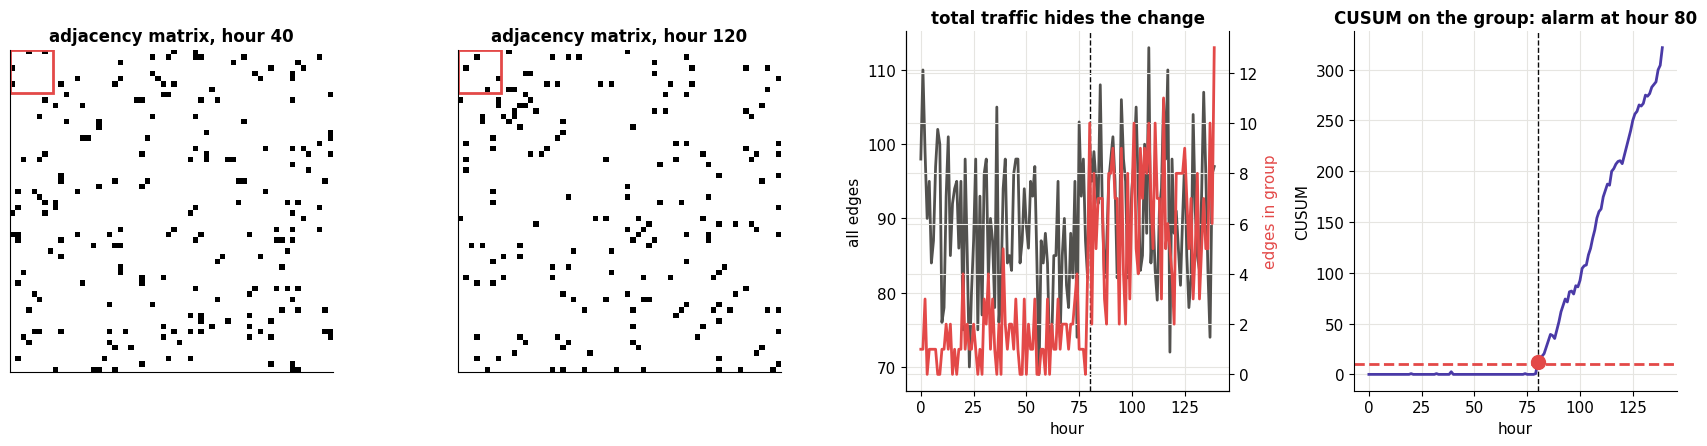

In [15]:
n_nodes, p0, p1, group, t_change, T = 60, 0.05, 0.25, np.arange(8), 80, 140
pairs_in = len(group) * (len(group) - 1) // 2; pairs_all = n_nodes * (n_nodes - 1) // 2
r_ = np.random.default_rng(3)
total_edges, group_edges, adj_snap = [], [], {}
for t in range(T):
    A = np.triu(r_.random((n_nodes, n_nodes)) < p0, 1)
    if t >= t_change:
        G_ = np.triu(r_.random((len(group), len(group))) < p1, 1); A[np.ix_(group, group)] = G_
    total_edges.append(A.sum()); group_edges.append(A[np.ix_(group, group)].sum())
    if t in (40, 120): adj_snap[t] = A | A.T
group_edges = np.array(group_edges)
llr_bin = lambda k: k * np.log(p1 / p0) + (pairs_in - k) * np.log((1 - p1) / (1 - p0))   # binomial log-likelihood ratio
Wg = cusum(group_edges, llr_bin)
alarm_g = int(np.argmax(Wg > 10))

fig = plt.figure(figsize=(17, 4.6))
for pos, t in [(1, 40), (2, 120)]:
    ax = fig.add_subplot(1, 4, pos); ax.imshow(adj_snap[t], cmap="Greys", interpolation="nearest")
    ax.set(title=f"adjacency matrix, hour {t}", xticks=[], yticks=[]); ax.add_patch(plt.Rectangle((-0.5, -0.5), 8, 8, fill=False, ec=C["red"], lw=2))
ax = fig.add_subplot(1, 4, 3); ax.plot(total_edges, color=C["muted"], label="all edges"); ax.axvline(t_change, color=C["ink"], ls="--", lw=1)
ax2 = ax.twinx(); ax2.plot(group_edges, color=C["red"], label="edges inside the group"); ax2.spines["right"].set_visible(True)
ax.set(xlabel="hour", ylabel="all edges", title="total traffic hides the change"); ax2.set_ylabel("edges in group", color=C["red"])
ax = fig.add_subplot(1, 4, 4); ax.plot(Wg, color=C["violet"], lw=2); ax.axhline(10, color=C["red"], ls="--"); ax.axvline(t_change, color=C["ink"], ls="--", lw=1)
ax.scatter(alarm_g, Wg[alarm_g], s=100, color=C["red"], zorder=3); ax.set(xlabel="hour", ylabel="CUSUM", title=f"CUSUM on the group: alarm at hour {alarm_g}")
fig.tight_layout(); plt.show()

The group's block in the adjacency matrix (red square) fills in after hour 80, while the overall edge count moves by a few percent, well within its normal hour-to-hour noise. CUSUM on the subgraph alarms in the very first hour after the change: with a fivefold jump in the group's edge probability, a single hour of evidence is already overwhelming. Real systems don't know **which** subgraph will change, so they scan many candidate subgraphs (or use spectral statistics) and correct for the multiple comparisons, which is the research behind the Twitter and news examples on ISYE's slides.

---
## 12. Summary

| Family | Method | Normal = | Needs | Strengths | Watch out for |
|---|---|---|---|---|---|
| Statistical | Gaussian / Mahalanobis | inside an ellipse | mean, covariance | fast, χ² thresholds | non-Gaussian data |
| | Robust covariance (MCD) | inside the core's ellipse | — | resists contaminated training data | needs $m \gg d$ |
| | KDE | high estimated density | bandwidth | any shape | high dimensions |
| Geometric | One-class SVM / SVDD | inside a (kernel) ball | ν, γ | flexible boundary, sparse | tuning without labels |
| | Isolation forest | hard to isolate | # trees | scales, high-dim, few assumptions | axis-aligned cuts |
| | LOF | as dense as its neighbors | k | varying densities | cost, k |
| Sequential | CUSUM | log-likelihood ratios that keep $W \approx 0$ | $f_0$, $f_1$ (or a shift size) | detects small persistent changes fast | known pre/post distributions |

**The big ideas:** model normal, not abnormal; define "far" with the data's own geometry (Mahalanobis); make the model robust when the training data is contaminated; a threshold is a hypothesis test, so choose it to control false alarms, and remember that rare events make most alarms false; when data arrives over time, accumulate evidence (CUSUM) instead of judging points one at a time.

That completes Part 2. Every method so far has been a fixed, hand-designed function family: lines, trees, Gaussians, low-rank matrices. Part 3 starts with **neural networks** (notebook 19), which learn their own features.

### ✏️ Exercises

1. Show that for a Gaussian density, $f_0(x) \le \varepsilon$ is equivalent to $(x - \mu)^\top\Sigma^{-1}(x - \mu) \ge b$, and find $b$ in terms of $\varepsilon$, $d$, and $|\Sigma|$.
2. HW4 Q7: derive the dual of the minimum enclosing ball step by step, and use complementary slackness to show that points strictly inside the ball have $\alpha_i = 0$. Then verify numerically with `min_enclosing_ball`.
3. Prove that a C-step never increases the determinant of the subset's covariance (hint: the Mahalanobis distances of the new subset sum to at most $hd$ under the old fit).
4. HW4 Q6: for $f_0 = \mathcal{N}(0, 1)$ and $f_1 = \mathcal{N}(0.5, 1.5)$ (note the *variance* changes too), derive the CUSUM increment $\log f_1(x)/f_0(x)$, then simulate 100 points from $f_0$ followed by 100 from $f_1$ and plot $W_k$.
5. Repeat section 8 with **10% of the training set replaced by malignant tumors** (outlier detection). Which detectors degrade, and does robust covariance now help?
6. Use the digits dataset as an OOD test: train a one-class SVM on digits 0–4 and score digits 5–9. Which digits look most "in-distribution" and why?
7. In section 11, suppose you don't know the group. Scan all groups of 8 consecutive node IDs (only some contain the true group) with one CUSUM each. How does the false-alarm rate change, and how should the threshold be adjusted?

### References

- ISYE 4600 W11 (Anomaly Detection) and HW4 Q5(4), Q6, Q7.
- P. Rousseeuw & K. Van Driessen, *A Fast Algorithm for the Minimum Covariance Determinant Estimator*, Technometrics (1999).
- D. Tax & R. Duin, *Support Vector Data Description*, Machine Learning (2004); B. Schölkopf et al., *Estimating the Support of a High-Dimensional Distribution*, Neural Computation (2001).
- F. T. Liu, K. M. Ting & Z.-H. Zhou, *Isolation Forest*, ICDM (2008); M. Breunig et al., *LOF: Identifying Density-Based Local Outliers*, SIGMOD (2000).
- E. S. Page, *Continuous Inspection Schemes*, Biometrika (1954); G. Lorden, *Procedures for Reacting to a Change in Distribution*, Annals of Mathematical Statistics (1971).
- J. Neyman & E. Pearson, *On the Problem of the Most Efficient Tests of Statistical Hypotheses* (1933).
- V. Chandola, A. Banerjee & V. Kumar, *Anomaly Detection: A Survey*, ACM Computing Surveys (2009).

**Next → [19 · Neural Networks](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/19_neural_networks.ipynb)**